# Breast Cancer Detection using a Neural Network

## 1. Introduction

**Objective**: Build, train and evaluate a feedforward neural network that
classifies a breast tumor as **Benign** or **Malignant** using diagnostic
measurements from the Breast Cancer Wisconsin (Diagnostic) dataset.

The workflow covers data loading, exploration, preprocessing, model
construction, training, and evaluation, followed by deployment through a
Streamlit web application.


## 2. Import Libraries

In [1]:
import json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

RANDOM_STATE = 42


I0000 00:00:1790488336.336065     923 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790488336.336711     923 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1790488336.557772     923 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1790488338.195899     923 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790488338.196398     923 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 3. Load Dataset

The dataset (`data.csv`) is the Breast Cancer Wisconsin (Diagnostic)
dataset: 569 samples, an `id` column, a `diagnosis` target (`M`/`B`), 30
real numeric diagnostic features (10 measurements × mean / standard error /
worst), and one empty placeholder column from the CSV export.


In [2]:
data = pd.read_csv('data.csv')
print("Raw dataset shape:", data.shape)
data.head()


Raw dataset shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## 4. Data Exploration

In [3]:
print("Columns:", list(data.columns))
print()
print("Missing values per column:")
print(data.isnull().sum())


Columns: ['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Missing values per column:
id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se  

The placeholder column `Unnamed: 32` is empty for **all 569 rows** and
carries no information, so it is excluded from the feature set below.


## 5. Data Preprocessing

### Remove Non-Predictive Columns


In [4]:
cols_to_drop = [c for c in ['id', 'Unnamed: 32'] if c in data.columns]
print("Dropping columns:", cols_to_drop)
data = data.drop(columns=cols_to_drop)

assert data.isnull().sum().sum() == 0, "Unexpected missing values remain!"
print("Shape after cleaning:", data.shape)
print("Missing values after cleaning:", data.isnull().sum().sum(), "(verified)")


Dropping columns: ['id', 'Unnamed: 32']
Shape after cleaning: (569, 31)
Missing values after cleaning: 0 (verified)


### Target Encoding

In [5]:
le = LabelEncoder()
data['diagnosis'] = le.fit_transform(data['diagnosis'])
print("Label mapping:", dict(zip(le.classes_, le.transform(le.classes_))))
data['diagnosis'].value_counts()


Label mapping: {'B': np.int64(0), 'M': np.int64(1)}


diagnosis
0    357
1    212
Name: count, dtype: int64

### Feature / Target Separation

In [6]:
X = data.drop(columns=['diagnosis'])
y = data['diagnosis']

feature_names = list(X.columns)
print("Final feature count:", len(feature_names))
assert len(feature_names) == 30
assert 'id' not in feature_names
assert 'Unnamed: 32' not in feature_names
assert 'diagnosis' not in feature_names
print("Leakage check passed: id, Unnamed: 32, diagnosis are not in X")
feature_names


Final feature count: 30
Leakage check passed: id, Unnamed: 32, diagnosis are not in X


['radius_mean',
 'texture_mean',
 'perimeter_mean',
 'area_mean',
 'smoothness_mean',
 'compactness_mean',
 'concavity_mean',
 'concave points_mean',
 'symmetry_mean',
 'fractal_dimension_mean',
 'radius_se',
 'texture_se',
 'perimeter_se',
 'area_se',
 'smoothness_se',
 'compactness_se',
 'concavity_se',
 'concave points_se',
 'symmetry_se',
 'fractal_dimension_se',
 'radius_worst',
 'texture_worst',
 'perimeter_worst',
 'area_worst',
 'smoothness_worst',
 'compactness_worst',
 'concavity_worst',
 'concave points_worst',
 'symmetry_worst',
 'fractal_dimension_worst']

## 6. Train-Test Split

An 80/20 split is used with `stratify=y` so that the Benign/Malignant class
ratio (about 63%/37%) is preserved in both the training and test sets. This
matters because the classes are imbalanced, and without stratification a
single random split could over- or under-represent the malignant class in
the test set, making the reported metrics less reliable.


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True))
print("Test class balance:\n", y_test.value_counts(normalize=True))


Train shape: (455, 30)  Test shape: (114, 30)
Train class balance:
 diagnosis
0    0.626374
1    0.373626
Name: proportion, dtype: float64
Test class balance:
 diagnosis
0    0.631579
1    0.368421
Name: proportion, dtype: float64


## 7. Feature Scaling

`StandardScaler` is fit **only on `X_train`**, then used to transform both
`X_train` and `X_test`. Fitting on the full dataset before splitting would
leak information about the test set's distribution into training. The
fitted scaler is saved to `scaler.pkl` so the Streamlit app uses identical
preprocessing at inference time.


In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

assert not np.isnan(X_train_scaled).any()
assert not np.isnan(X_test_scaled).any()
print("No NaNs in scaled train/test data (verified)")

joblib.dump(scaler, 'scaler.pkl')
print("Saved fitted scaler -> scaler.pkl")


No NaNs in scaled train/test data (verified)
Saved fitted scaler -> scaler.pkl


## 8. Neural Network Construction

A compact, fully-connected feedforward network:

- Input: 30 features
- `Dense(32, activation='relu')`
- `Dense(16, activation='relu')`
- `Dense(1, activation='sigmoid')` (binary classification output)

This architecture is intentionally simple: the dataset is small (569
samples) and low dimensional, so a compact network is enough to model it
while remaining easy to explain.


In [9]:
model = Sequential([
    tf.keras.Input(shape=(X_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid'),
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()


E0000 00:00:1790488338.624877     923 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Model Training

Trained for 50 epochs with an internal `validation_split=0.2` (taken from
the training set only) to monitor generalization during training. The test
set is not used until the final evaluation step.


In [10]:
history = model.fit(
    X_train_scaled, y_train,
    epochs=50,
    validation_split=0.2,
    verbose=2,
)


Epoch 1/50


12/12 - 1s - 78ms/step - accuracy: 0.6071 - loss: 0.6179 - val_accuracy: 0.7473 - val_loss: 0.5518


Epoch 2/50


12/12 - 0s - 13ms/step - accuracy: 0.9066 - loss: 0.4468 - val_accuracy: 0.9231 - val_loss: 0.4073


Epoch 3/50


12/12 - 0s - 12ms/step - accuracy: 0.9478 - loss: 0.3374 - val_accuracy: 0.9341 - val_loss: 0.3054


... (90 outputs left out)

Epoch 49/50


12/12 - 0s - 12ms/step - accuracy: 0.9973 - loss: 0.0103 - val_accuracy: 0.9670 - val_loss: 0.1216


Epoch 50/50


12/12 - 0s - 12ms/step - accuracy: 0.9973 - loss: 0.0097 - val_accuracy: 0.9670 - val_loss: 0.1238


## 10. Evaluation

Evaluated on the held-out test set (114 samples, 20% of the data), which was
never used for training, validation-split monitoring, or scaler fitting.


In [12]:
y_pred_prob = model.predict(X_test_scaled, verbose=0)
y_pred_labels = (y_pred_prob > 0.5).astype(int).ravel()

test_accuracy = accuracy_score(y_test, y_pred_labels)
print("Test Accuracy:", test_accuracy)

keras_eval = model.evaluate(X_test_scaled, y_test, verbose=0)
print("Keras model.evaluate() -> loss: {:.4f}, accuracy: {:.4f}".format(*keras_eval))


Test Accuracy: 0.9736842105263158
Keras model.evaluate() -> loss: 0.0670, accuracy: 0.9737


### Save Trained Model

In [15]:
model.save('breast_cancer_model.h5')
print("Saved model -> breast_cancer_model.h5")


Saved model -> breast_cancer_model.h5


### Save Scaler

In [16]:
import os
print("scaler.pkl exists:", os.path.exists('scaler.pkl'))
print("breast_cancer_model.h5 exists:", os.path.exists('breast_cancer_model.h5'))


scaler.pkl exists: True
breast_cancer_model.h5 exists: True


## 11. Confusion Matrix

In [13]:
cm = confusion_matrix(y_test, y_pred_labels)
print("Confusion Matrix (rows=true, cols=predicted, order=[Benign, Malignant]):")
print(cm)


Confusion Matrix (rows=true, cols=predicted, order=[Benign, Malignant]):
[[70  2]
 [ 1 41]]


## 12. Classification Report

In [14]:
report = classification_report(y_test, y_pred_labels, target_names=['Benign', 'Malignant'])
print(report)


              precision    recall  f1-score   support

      Benign       0.99      0.97      0.98        72
   Malignant       0.95      0.98      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



## 13. Training Curves

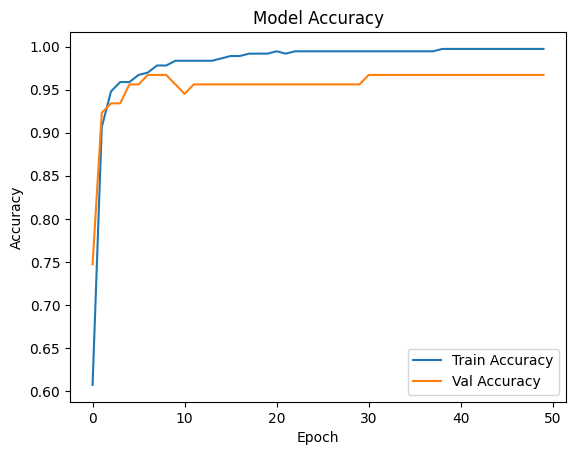

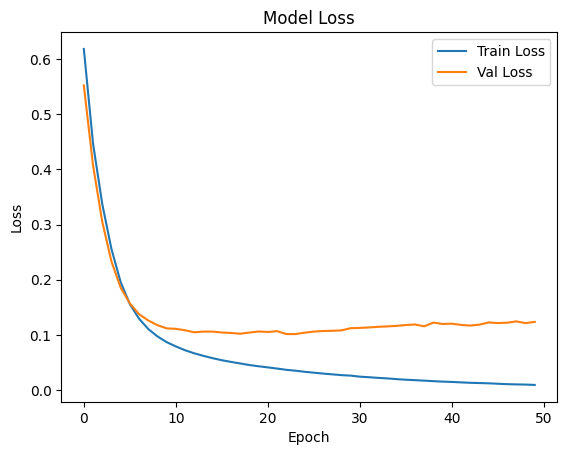

In [11]:
plt.figure()
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

plt.figure()
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


## 14. Conclusion

- The model is trained on 30 real diagnostic features.
- The scaler used at inference time in the Streamlit app is the exact
  object fit on the training split, saved to `scaler.pkl`.
- Test-set accuracy, precision, recall, F1-score, and the confusion matrix
  above reflect the actual results of this pipeline.
- Known limitations: no k-fold cross-validation, no hyperparameter search,
  no dropout/regularization, and no external validation set. This is
  appropriate for a project of this scope, but is worth mentioning
  proactively when discussing the project.
